In [15]:
import itertools
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from scipy.stats import studentized_range
from patsy import dmatrix, dmatrices
from statsmodels.formula.api import ols
import statsmodels.stats.multicomp as mc

In [16]:
data = {
    'Parcela' : ['P1', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7', 'P8', 'P9', 'P10', 'P11', 'P12'],
    'Tratamiento': ["Ninguno", "Fert_A", "Fert_B", "Fert_C",
                    "Ninguno", "Fert_A", "Fert_B", "Fert_C",
                    "Ninguno", "Fert_A", "Fert_B", "Fert_C"],
    'Rendimiento' : [480, 500, 600, 550, 465, 525, 620, 575, 470, 490, 590, 560],
    'Humedad': [45, 42, 48, 50, 55, 53, 57, 56, 65, 67, 63, 62]
}

df = pd.DataFrame(data)
print(df)

   Parcela Tratamiento  Rendimiento  Humedad
0       P1     Ninguno          480       45
1       P2      Fert_A          500       42
2       P3      Fert_B          600       48
3       P4      Fert_C          550       50
4       P5     Ninguno          465       55
5       P6      Fert_A          525       53
6       P7      Fert_B          620       57
7       P8      Fert_C          575       56
8       P9     Ninguno          470       65
9      P10      Fert_A          490       67
10     P11      Fert_B          590       63
11     P12      Fert_C          560       62


In [17]:
alpha = 0.05

# 1. Exploración

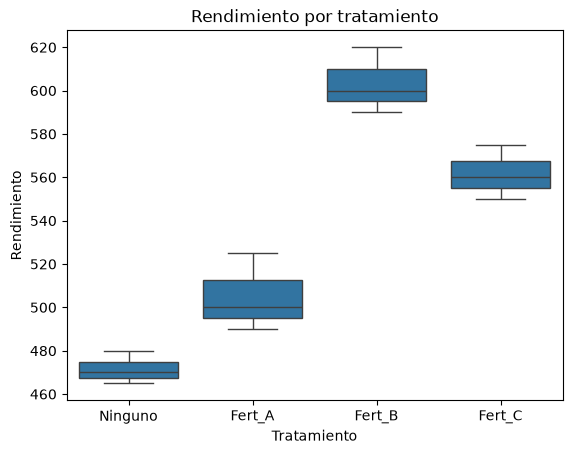

In [18]:
sns.boxplot(x = "Tratamiento", y = "Rendimiento", data = df)
plt.title("Rendimiento por tratamiento")
plt.show()

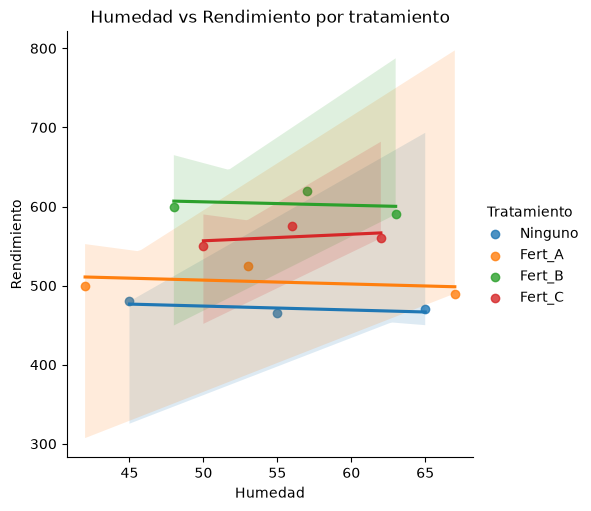

In [19]:
sns.lmplot(data = df, x = "Humedad", y = "Rendimiento", hue = "Tratamiento")
plt.title("Humedad vs Rendimiento por tratamiento")
plt.show()

# 2. Supuestos 6 y 7
H0: La humedad media es igual en todos los grupos

In [20]:
m_cov = ols("Humedad ~ Tratamiento", data = df).fit()
anova_table = sm.stats.anova_lm(m_cov, typ = 2)
p_value_s6 = anova_table.loc['Tratamiento', 'PR(>F)']
print(anova_table)

             sum_sq   df         F    PR(>F)
Tratamiento    8.25  3.0  0.031429  0.991921
Residual     700.00  8.0       NaN       NaN


In [21]:
print("No hay evidencia de que la humedad dependa del tratamiento"
      if p_value_s6 > alpha else "La humedad difiere entre tratamientos")

No hay evidencia de que la humedad dependa del tratamiento


# Si falla el supuesto 6:
Alternativas: usar la humedad como bloque (rangos) o ANOVA sin covarianza. Si el tratamiento modificó la humedad, no hacer el ajuste por la covarianza

H0: la pendiente de Humedad es la misma en todos los tratamientos

In [22]:
m_adit = ols("Rendimiento ~ Tratamiento + Humedad", data = df).fit()
m_int = ols("Rendimiento ~ Tratamiento + Humedad", data = df).fit()
anova_table2 = sm.stats.anova_lm(m_cov, typ = 2)
print(anova_table)

             sum_sq   df         F    PR(>F)
Tratamiento    8.25  3.0  0.031429  0.991921
Residual     700.00  8.0       NaN       NaN


In [23]:
p_value_s7 = anova_table2.iloc[-1, 1]

heterogenea = p_value_s7 < alpha
modelo = m_int if heterogenea else m_adit

In [24]:
anova_table3 = sm.stats.anova_lm(modelo, typ = 2)
print(anova_table3)
print(modelo.summary())

                   sum_sq   df          F    PR(>F)
Tratamiento  30935.261707  3.0  49.296416  0.000045
Humedad         85.750000  1.0   0.409937  0.542383
Residual      1464.250000  7.0        NaN       NaN
                            OLS Regression Results                            
Dep. Variable:            Rendimiento   R-squared:                       0.955
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                     37.00
Date:                Thu, 22 Oct 2026   Prob (F-statistic):           8.50e-05
Time:                        17:24:12   Log-Likelihood:                -45.852
No. Observations:                  12   AIC:                             101.7
Df Residuals:                       7   BIC:                             104.1
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
  

# Supuestos 2 y 4
Shapiro-Wilk (Normalidad). H0: Los datos son normales

Levene (Homocedasticidad). H0: Las varianzas son iguales entre todos los grupos

In [25]:
res = modelo.resid
print(f"Shapiro-Wilk {stats.shapiro(res)[1]}")
niveles = sorted(df["Tratamiento"].unique())
print(f"Levene {stats.levene(*[res[df["Tratamiento"] == t] for t in niveles])}")

Shapiro-Wilk 0.17403004351880247
Levene LeveneResult(statistic=np.float64(0.19564683768615848), pvalue=np.float64(0.8964625657893147))


# Post Hoc

In [27]:
df["Rendimiento_ajustado"] = df["Rendimiento"] - (df["Humedad"] - df["Humedad"].mean()) * modelo.params["Humedad"]

comp_naive = mc.MultiComparison(df["Rendimiento_ajustado"], df["Tratamiento"])
post_hoc_res = comp_naive.tukeyhsd()
print(post_hoc_res.summary())

   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
group1  group2  meandiff p-adj    lower    upper   reject
---------------------------------------------------------
Fert_A  Fert_B   99.0333 0.0001   63.6592 134.4075   True
Fert_A  Fert_C   57.3667 0.0037   21.9925  92.7408   True
Fert_A Ninguno  -32.9833 0.0679  -68.3575   2.3908  False
Fert_B  Fert_C  -41.6667 0.0227  -77.0408  -6.2925   True
Fert_B Ninguno -132.0167    0.0 -167.3908 -96.6425   True
Fert_C Ninguno    -90.35 0.0002 -125.7242 -54.9758   True
---------------------------------------------------------


In [28]:
comp_naive = mc.MultiComparison(df["Rendimiento_ajustado"], df["Tratamiento"])
post_hoc_res = comp_naive.tukeyhsd()
print(post_hoc_res.summary())

   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
group1  group2  meandiff p-adj    lower    upper   reject
---------------------------------------------------------
Fert_A  Fert_B   99.0333 0.0001   63.6592 134.4075   True
Fert_A  Fert_C   57.3667 0.0037   21.9925  92.7408   True
Fert_A Ninguno  -32.9833 0.0679  -68.3575   2.3908  False
Fert_B  Fert_C  -41.6667 0.0227  -77.0408  -6.2925   True
Fert_B Ninguno -132.0167    0.0 -167.3908 -96.6425   True
Fert_C Ninguno    -90.35 0.0002 -125.7242 -54.9758   True
---------------------------------------------------------
